## DB Scan

In [19]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv(r"C:\Users\Karan\Downloads\Mall_Customers.csv")
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [21]:
x = df[['Annual Income (k$)',
       'Spending Score (1-100)']]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [22]:
model = DBSCAN(eps=0.35, min_samples = 4)
labels = model.fit_predict(x_scaled)
df['cluster'] = labels
df['cluster'].value_counts()

cluster
 3    89
 4    32
 5    23
 0    17
-1    16
 1    12
 2     7
 6     4
Name: count, dtype: int64

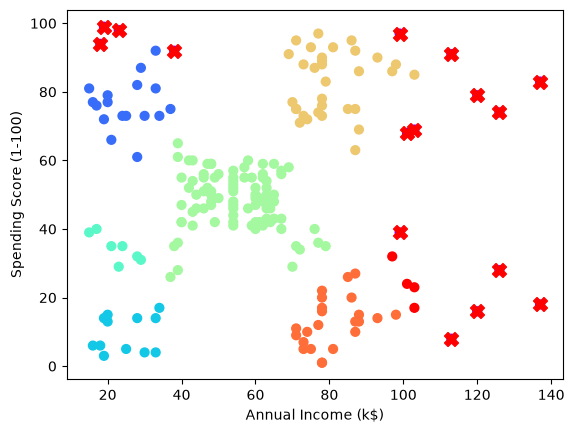

In [23]:
no_of_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_points = np.sum(labels==-1)
#just for info^

noise_df = df[['Annual Income (k$)','Spending Score (1-100)' ]][df['cluster'] ==-1]

plt.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels, cmap='rainbow', s=40)
plt.scatter(noise_df['Annual Income (k$)'], noise_df['Spending Score (1-100)'], marker='X', c='red', s=100)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


In [24]:
core_indices = model.core_sample_indices_
core_indices

array([  1,   2,   3,   4,   5,   6,   8,   9,  10,  12,  13,  14,  15,
        16,  17,  18,  20,  21,  22,  23,  24,  25,  26,  28,  29,  31,
        35,  37,  39,  40,  42,  43,  44,  45,  46,  47,  48,  49,  50,
        51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,
        64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,
        77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,
        90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
       103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115,
       116, 117, 118, 119, 120, 121, 122, 123, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 170,
       171, 172, 173, 174, 175, 176, 177, 178, 179, 181, 183, 186, 188])

## PCA (Principal Component Analysis)

In [25]:
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA

In [26]:
data = load_breast_cancer(as_frame=True)
x = data.data
x.shape
# 30 features!! too much

(569, 30)

In [27]:
data.target.value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [32]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

pca = PCA(n_components = 2)
x_pca = pca.fit_transform(x_scaled)

pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum()
# so that means the 2 features we have rn explain 63% of the variance of the dataset

(array([0.44272026, 0.18971182]), np.float64(0.6324320765155946))

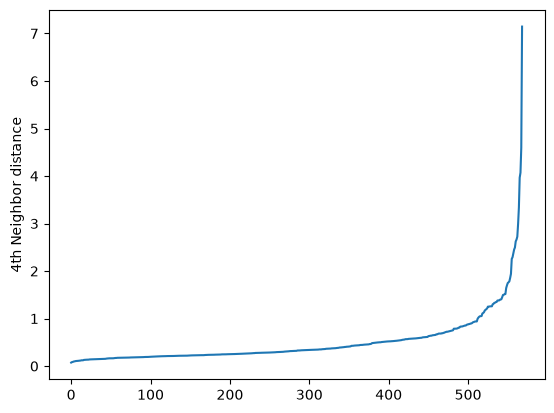

In [38]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4)
nn.fit(x_pca)
dist, i = nn.kneighbors(x_pca)

plt.plot(np.sort(dist[:, -1]))
plt.ylabel('4th Neighbor distance')
plt.show()

1.3ish??

In [40]:
db = DBSCAN(eps=1.3, min_samples=4)
labels = db.fit_predict(x_pca)
print('Clusters:', len(set(labels))-(1 if -1 in labels else 0))
print('Noise Points:', np.sum(labels==-1))

Clusters: 3
Noise Points: 22


In [41]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

y = data.target
print("ARI:", adjusted_rand_score(y, labels))
print("NMI:", normalized_mutual_info_score(y, labels))

ARI: 0.040209845538531075
NMI: 0.06160053923529087


In [42]:
print(pd.crosstab(labels, y, rownames=["cluster"], colnames=["true"]))


true       0    1
cluster          
-1        17    5
 0         6    0
 1       189  346
 2         0    6


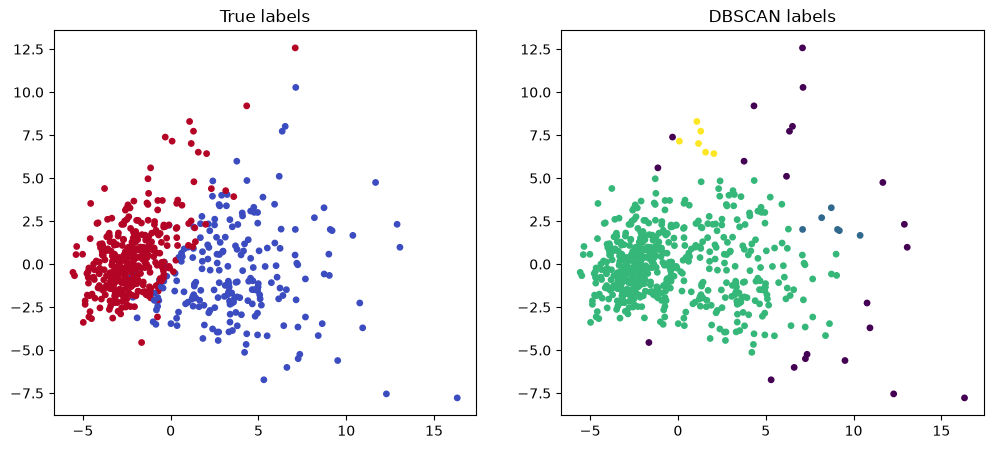

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap="coolwarm", s=15)
ax[0].set_title("True labels")
ax[1].scatter(x_pca[:, 0], x_pca[:, 1], c=labels, cmap="viridis", s=15)
ax[1].set_title("DBSCAN labels")
plt.show()

In [46]:
from sklearn.cluster import KMeans

kmean = KMeans(n_clusters=2)
label1 = kmean.fit_predict(x_pca)
print("ARI:", adjusted_rand_score(y, label1))
print("NMI:", normalized_mutual_info_score(y, label1))

ARI: 0.6649625478425899
NMI: 0.5474036117168154


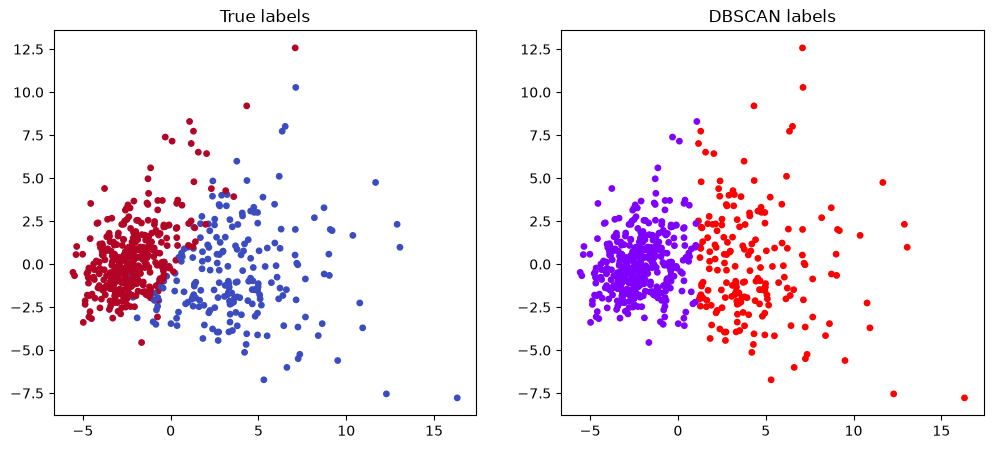

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap="coolwarm", s=15)
ax[0].set_title("True labels")
ax[1].scatter(x_pca[:, 0], x_pca[:, 1], c=label1, cmap="rainbow", s=15)
ax[1].set_title("DBSCAN labels")
plt.show()

### Basically DBSCAN was 💩 for this dataset